# Lab 1: Simple Linear Regression

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

An insurance company charges every client a different annual premium. The goal is
to determine whether the client's body mass index (BMI) can predict how much they
are charged, using a simple linear regression model.

The response variable (Y) is `charges`, the amount billed to the client in
dollars, and the predictor variable (X) is `bmi`, the body mass index.

The starting hypothesis is that a higher BMI means a higher health risk and
therefore a more expensive premium.

### Libraries

In [1]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation and normality tests
from scipy.stats import pearsonr, spearmanr, shapiro

# Model
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Model persistence
import joblib

## Data Understanding (CRISP-DM 2)

In [2]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'insurance.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
insurance = pd.read_csv(path)

# First records
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Each row is one client and each column one of the seven variables recorded about
them. Three are text (`sex`, `smoker`, `region`) and four are numbers (`age`,
`bmi`, `children`, `charges`), and the two the lab works with, `bmi` and
`charges`, are both continuous, which is what a linear regression needs on each
side of the equation.

In [3]:
# Number of records
print("Record count:", len(insurance))
# Number of columns
print("Column count:", len(insurance.columns))
# Rows and columns
print("Rows and columns:", insurance.shape)
# Dataset information
insurance.info()

Record count: 1338
Column count: 7
Rows and columns: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


The dataset holds 1,338 clients and 7 columns. What `info()` adds is the count
of non-null values per column, 1,338 in every one of them, so no record is
missing any field, and the data type of each column, which confirms that `bmi`
and `charges` are read as decimal numbers and not as text.

In [4]:
# Check for null values
print(insurance.isnull().any().sum(), ' / ', len(insurance.columns))

0  /  7


The dataset has no missing values, so there is nothing to impute.
The two variables used here (`bmi` and `charges`) are continuous quantitative
variables, which is what a linear regression requires.

Missing values are not the only thing that has to be checked before modelling.
A record can be complete and still be wrong, and the most common case is the
same observation stored twice.

In [5]:
# Check for duplicated records
print("Duplicated rows:", insurance.duplicated().sum())

# The records involved
insurance[insurance.duplicated(keep=False)]

Duplicated rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Two clients share all seven values. Before deleting anything the question has to
be answered: is this the same person recorded twice, or two different clients
who happen to coincide? Removing a legitimate observation is as much of a
mistake as keeping a repeated one.

The dataset has no client identifier, so the answer has to come out of the data
itself. If `charges` were fully determined by the other six variables, two
different clients with identical characteristics would necessarily be billed the
same amount and the coincidence would be legitimate. The check below takes every
group of clients that share all six predictors and asks whether they pay the
same.

In [6]:
# Do clients who share every predictor pay the same amount?
predictors = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
groups = insurance.groupby(predictors)['charges'].agg(['size', 'nunique'])
repeated = groups[groups['size'] > 1]

print("Groups of clients sharing every predictor:", len(repeated))
print("  paying different amounts:", (repeated['nunique'] > 1).sum())
print("  paying the same amount  :", (repeated['nunique'] == 1).sum())

# Remove the duplicated record
insurance = insurance.drop_duplicates().reset_index(drop=True)
print("\nRecords after removing the duplicate:", len(insurance))

Groups of clients sharing every predictor: 3
  paying different amounts: 2
  paying the same amount  : 1

Records after removing the duplicate: 1337


Three groups of clients share the six predictors. One of them is the pair under
investigation itself, the only group where everyone pays the same, so it cannot
serve as its own evidence and the answer has to come from the other two. In both
of them the clients are billed different amounts. So `charges` is not determined
by the other variables: it carries an individual component, and two different
clients have no reason to land on the same figure down to the fourth decimal.

That settles the question. A match as exact as 1,639.5631 is one record entered
twice rather than a coincidence, so the row is removed and the client counts
once instead of twice.

The change to the table is one row out of 1,338, and that is the expected
outcome. Cleaning is not judged by how much it moves the numbers but by whether
the table ends up representing what it claims to represent, which here is one
row per client.

In [7]:
# Describe the dataset
insurance[['bmi', 'charges']].describe().round(2)

,bmi,charges
count,1337.00,1337.00
mean,30.66,13279.12
std,6.10,12110.36
min,15.96,1121.87
25%,26.29,4746.34
50%,30.40,9386.16
75%,34.70,16657.72
max,53.13,63770.43


These ranges define how far the model may be used to predict: outside them
the prediction would be an extrapolation.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

In [8]:
# Correlation matrix of the numeric variables
correlation = insurance.corr(numeric_only=True)
print(correlation)

               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


The table gives the correlation of every pair of numeric variables, on a scale
from -1 to +1, and the diagonal is 1 because a variable is identical to itself.
The row that matters is `charges`: it correlates 0.298 with `age`, 0.198 with
`bmi` and 0.067 with `children`. So `bmi` is the second variable most related to
the price, but 0.198 is a weak relationship, and that number already sets the
ceiling of what a model built only on `bmi` can achieve.

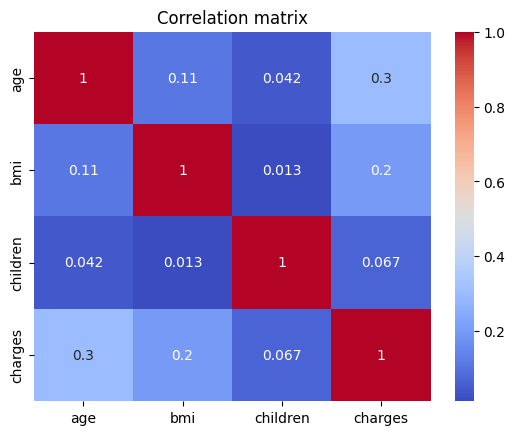

In [9]:
sns.heatmap(correlation, cmap='coolwarm', annot=True)
plt.title('Correlation matrix')
plt.show()

The heatmap is the table printed above drawn in colour. Each square holds the
correlation between the variable of its row and the one of its column, on a
scale from -1 to +1, and the diagonal is always 1 because every variable
correlates perfectly with itself. Warm squares mark pairs that grow together and
cool squares pairs that move in opposite directions, so the strong relationships
can be found without reading every number.

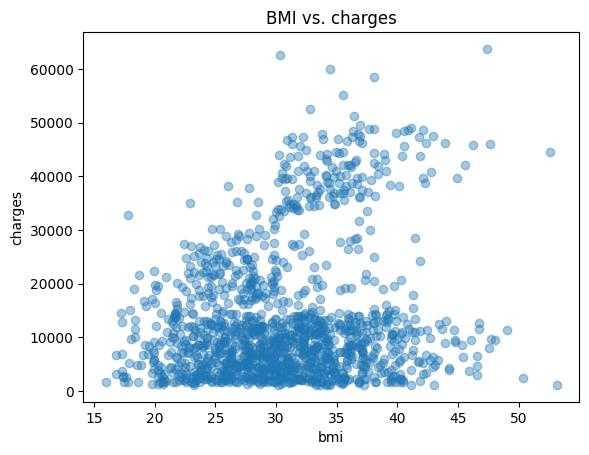

In [10]:
# Scatter plot between BMI and the amount charged
plt.scatter(insurance['bmi'], insurance['charges'], alpha=0.4)
plt.title('BMI vs. charges')
plt.xlabel('bmi')
plt.ylabel('charges')
plt.show()

The scatter plot shows no clear straight line: the same BMI maps to very
different amounts, and two separate bands of points stand out. The cloud also
widens to the right, a sign of heteroscedasticity, so the model error will
not be constant along BMI.

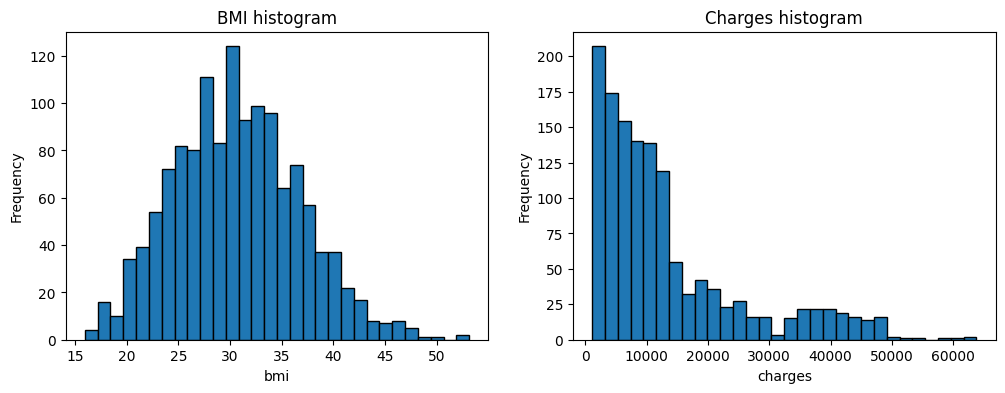

In [11]:
# Histograms of both variables
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(insurance['bmi'], bins=30, edgecolor='black')
ax[0].set(title='BMI histogram', xlabel='bmi', ylabel='Frequency')
ax[1].hist(insurance['charges'], bins=30, edgecolor='black')
ax[1].set(title='Charges histogram', xlabel='charges', ylabel='Frequency')
plt.show()

A histogram counts how many observations fall inside each range of values, so
its shape shows where the data piles up and whether one side reaches further
than the other. `bmi` forms a bell centred near 30 with both sides alike, while
`charges` piles up on the left and stretches into a long thin tail on the right,
which is the handful of clients paying far more than the rest.

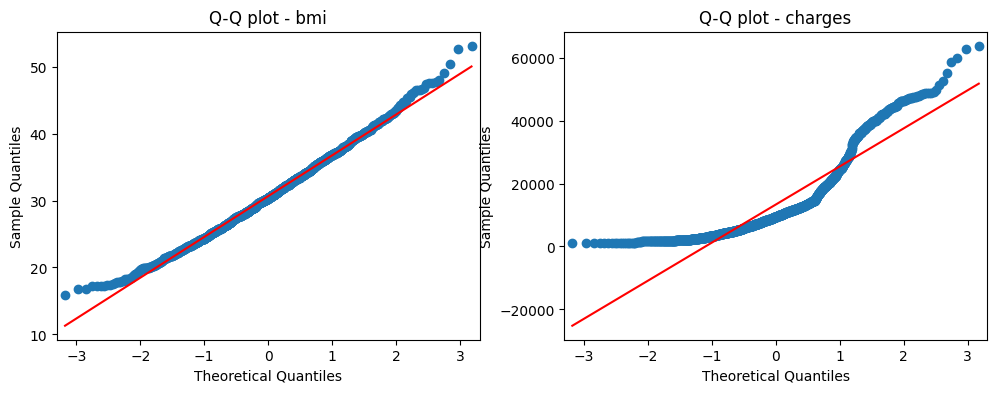

In [12]:
# Q-Q plots to assess normality
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sm.qqplot(insurance['bmi'], line='s', ax=ax[0])
ax[0].set_title('Q-Q plot - bmi')
sm.qqplot(insurance['charges'], line='s', ax=ax[1])
ax[1].set_title('Q-Q plot - charges')
plt.show()

The Q-Q plot asks the same question as the histogram, but with more precision:
it places the values the variable actually takes against the values a normal
variable with the same centre and spread would take. When both agree the points
sit on the diagonal, and points curving away at the ends mean the real data has
heavier or lighter tails than a normal distribution. Here `bmi` follows the
diagonal almost everywhere while `charges` lifts off it on the right, which is
the long tail of expensive clients seen again from another angle.

In [13]:
# Hypothesis test for normality (Shapiro-Wilk)
for col in ['bmi', 'charges']:
    statistic, p_value = shapiro(insurance[col])
    print(f'{col}: statistic = {statistic:.4f}, p-value = {p_value:.6f}')

bmi: statistic = 0.9939, p-value = 0.000026
charges: statistic = 0.8148, p-value = 0.000000


`bmi` looks symmetric and its Q-Q plot follows the diagonal, while
`charges` is unbalanced: most clients are cheap and a few are extremely
expensive, so the histogram has a long tail stretching to the right instead of
the same amount of data on each side of the centre. Shapiro-Wilk rejects
normality for both, especially for `charges`.

Since neither normality nor homoscedasticity holds, Pearson loses precision, so
Spearman is computed as well: it works on ranks and does not require those
conditions.

That long right tail of `charges` is what the data preparation step has to
correct before fitting the line, which is done next with a logarithmic
transformation.

In [14]:
# Pearson coefficient
pearson_r, pearson_p = pearsonr(insurance['bmi'], insurance['charges'])
print("Pearson correlation coefficient:", round(pearson_r, 4))
print("p-value:", pearson_p)

# Spearman coefficient
spearman_r, spearman_p = spearmanr(insurance['bmi'], insurance['charges'])
print("\nSpearman correlation coefficient:", round(spearman_r, 4))
print("p-value:", spearman_p)

Pearson correlation coefficient: 0.1984
p-value: 2.4680404264513685e-13

Spearman correlation coefficient: 0.1196
p-value: 1.1637179203181515e-05


The correlation is positive and significant (p-value far below 0.05, so
the relationship is not due to chance), but its magnitude is weak. Significance
only confirms that the relationship exists. The magnitude says it explains very
little. This already anticipates the outcome: the model will run, but it will
predict poorly.

### Logarithmic transformation of `charges`

Linear regression does not require the response variable to be normal, but it
does require the residuals to be. When `charges` has this long right tail, the
residuals inherit it and the spread grows with the fitted value, which
invalidates the p-values and the confidence intervals of the model.

Taking the natural logarithm compresses that tail (the few very expensive
clients) and leaves the variable balanced, with a similar amount of data on both
sides of the centre, so the assumption holds. `bmi` is left untouched: it is
already balanced, so there is nothing to correct on the predictor side.

How unbalanced a variable is can be measured with a single number, which pandas
computes with `.skew()`: 0 means both sides weigh the same, a positive value
means the tail stretches to the right, and a negative value means it stretches
to the left. Anything roughly between -0.5 and 0.5 is considered balanced.

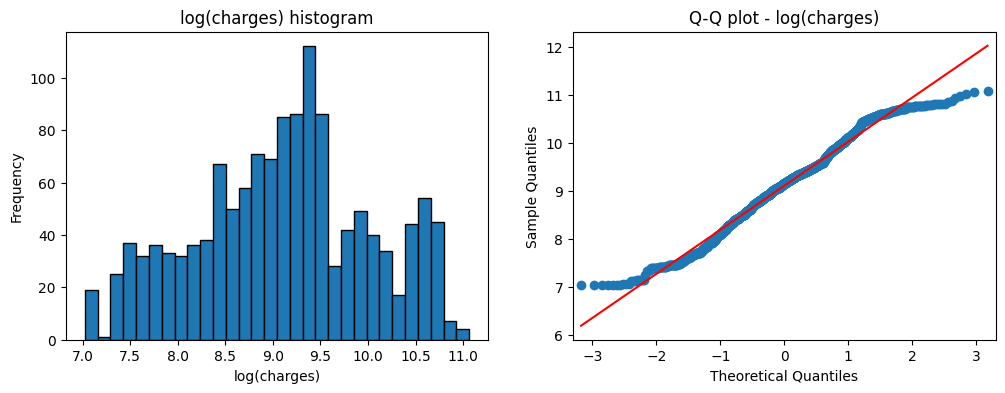

Imbalance of charges      : 1.515
Imbalance of log(charges) : -0.090
Shapiro-Wilk on log(charges): statistic = 0.9833, p-value = 2.573e-11


In [15]:
# Logarithmic transformation of the response variable
log_charges = np.log(insurance['charges'])

# Shape of the variable before and after the transformation
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(log_charges, bins=30, edgecolor='black')
ax[0].set(title='log(charges) histogram', xlabel='log(charges)', ylabel='Frequency')
sm.qqplot(log_charges, line='s', ax=ax[1])
ax[1].set_title('Q-Q plot - log(charges)')
plt.show()

# How unbalanced the variable is, before and after (0 means both sides weigh the same)
imbalance_before = insurance['charges'].skew()
imbalance_after = log_charges.skew()
print(f'Imbalance of charges      : {imbalance_before:.3f}')
print(f'Imbalance of log(charges) : {imbalance_after:.3f}')

# Normality test on the transformed variable
statistic, p_value = shapiro(log_charges)
print(f'Shapiro-Wilk on log(charges): statistic = {statistic:.4f}, p-value = {p_value:.3e}')

The imbalance drops from about 1.52 to roughly -0.09, so the variable goes from
having a long tail on the right to being practically even on both sides, and the
histogram and the Q-Q plot confirm it. Shapiro-Wilk still rejects normality, but
that test is extremely sensitive with 1,337 observations: what matters here is
that the shape of the distribution no longer has a long tail pulling the fit.

The model therefore becomes semi-logarithmic: `log(charges) ~ bmi`. Predictions
have to be converted back to dollars with the exponential function before they
can be read or compared.

## Machine Learning Model (CRISP-DM 4: Modeling)

The dataset is split into training and test sets so the model can be
measured on data it never saw, and the line is fitted by ordinary least
squares on the transformed response, `log(charges)`.

In [16]:
# Split the dataset into a training set and a test set
insurance_train, insurance_test = train_test_split(
    insurance[['bmi', 'charges']], test_size=0.2, random_state=42)

print(".................................Training..................................")
print(insurance_train.describe().round(2))
print(".................................Test......................................")
print(insurance_test.describe().round(2))

.................................Training..................................
           bmi   charges
count  1069.00   1069.00
mean     30.54  13030.20
std       6.05  11706.53
min      15.96   1121.87
25%      26.18   4747.05
50%      30.20   9290.14
75%      34.43  16450.89
max      53.13  62592.87
.................................Test......................................
          bmi   charges
count  268.00    268.00
mean    31.15  14272.01
std      6.28  13581.03
min     16.82   1131.51
25%     26.80   4731.71
50%     31.12   9535.65
75%     35.26  17781.10
max     48.07  63770.43


The ranges of both sets are compared, and the test observations that fall
outside the training range are removed to avoid extrapolation.

In [17]:
# Remove out-of-range data from the test set
bmi_min = insurance_train['bmi'].min()
bmi_max = insurance_train['bmi'].max()

before = len(insurance_test)
insurance_test = insurance_test[
    (insurance_test['bmi'] >= bmi_min) & (insurance_test['bmi'] <= bmi_max)].copy()

print(f'Training bmi range: {bmi_min:.2f} to {bmi_max:.2f}')
print(f'Observations removed from the test set: {before - len(insurance_test)}')

Training bmi range: 15.96 to 53.13
Observations removed from the test set: 0


The training set covers BMI values from 15.96 to 53.13, and no test client falls
outside that interval, so nothing had to be removed. The check is run anyway
because a prediction outside the range the model was trained on is an
extrapolation: the model would be inventing behaviour for BMI values it never
saw.

In [18]:
# Fit the simple linear regression model on the transformed response
X = sm.add_constant(insurance_train[['bmi']])
y = np.log(insurance_train['charges'])

reg_charges = sm.OLS(y, X).fit()

# Print the model summary
print(reg_charges.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     16.34
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           5.68e-05
Time:                        21:17:45   Log-Likelihood:                -1403.8
No. Observations:                1069   AIC:                             2812.
Df Residuals:                    1067   BIC:                             2822.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.5295      0.142     60.171      0.0

The summary is read in three places. `R-squared` at the top right, about 0.015,
is the share of the variation in `log(charges)` the model explains, so BMI
accounts for under 2 % of why one client pays more than another. The `coef`
column gives the equation, with `const` as the intercept and `bmi` as the slope.
The `P>|t|` column of `bmi`, around 0.00006, answers whether that slope could
really be zero and what is seen be luck, and being far below 0.05 says it could
not.

The two readings do not contradict each other. The relationship between BMI and
price is real, and it is also tiny.

In [19]:
# Equation of the fitted model
b0 = reg_charges.params['const']
b1 = reg_charges.params['bmi']
print(f'log(charges) = {b0:.4f} + {b1:.4f} * bmi')

# The same equation expressed in dollars
print(f'charges = {np.exp(b0):,.2f} * exp({b1:.4f} * bmi)')

# Percentage reading of the slope
print(f'Every extra BMI point multiplies the charge by {np.exp(b1):.4f}, '
      f'that is {100 * (np.exp(b1) - 1):.2f} % more.')

log(charges) = 8.5295 + 0.0184 * bmi
charges = 5,062.07 * exp(0.0184 * bmi)
Every extra BMI point multiplies the charge by 1.0186, that is 1.86 % more.


The transformation also changes how the coefficients are read.

The slope b1 is no longer dollars per BMI point. On a logarithmic response it
becomes a relative change: every extra BMI point multiplies the charge by
exp(b1), about 1.9 % more per point.

The intercept b0 is the log of the charge for a client with BMI = 0, which does
not exist. It is only where the line crosses the vertical axis and has no
real-world reading.

The `P>|t|` of `bmi` is below 0.05, so the variable does contribute significantly
to the model.

## Evaluation (CRISP-DM 5)

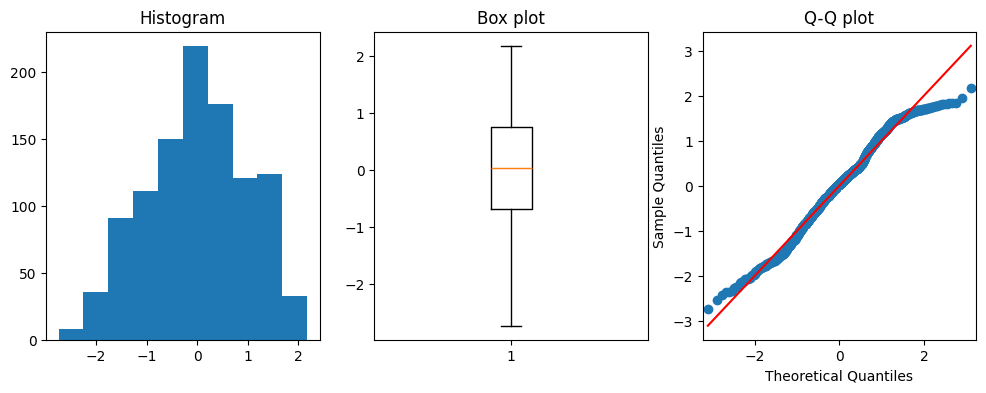

In [20]:
# Compute standardized residuals
residuals = reg_charges.get_influence().resid_studentized_internal

# Plots to inspect the standardized residuals
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].hist(residuals)
ax[0].set_title('Histogram')
ax[1].boxplot(residuals)
ax[1].set_title('Box plot')
sm.qqplot(residuals, line='s', ax=ax[2])
ax[2].set_title('Q-Q plot')
plt.show()

The three panels look at the same residuals in three ways. The histogram shows
their shape, which should be a bell centred on zero. The box plot summarises
them in five numbers: the orange line is the median error, the box holds the
middle half of the residuals, the whiskers reach as far as the errors that still
count as ordinary, and any circle beyond them is an observation the model missed
by an unusual amount. The Q-Q plot compares the residuals against a normal
distribution, so points along the diagonal mean the normality assumption holds.

The residuals are standardized, which means the axis is measured in standard
deviations instead of the units of the target, so a residual of 2 is an error
twice as large as the typical one and values beyond 3 are rare.

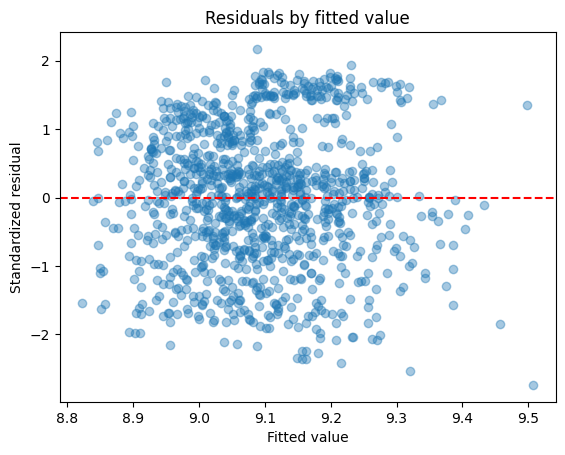

In [21]:
# Residuals against fitted values
plt.scatter(reg_charges.fittedvalues, residuals, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals by fitted value')
plt.xlabel('Fitted value')
plt.ylabel('Standardized residual')
plt.show()

This plot puts every residual against the value the model predicted for that
observation, with the dashed red line at zero marking a perfect prediction. What
is being looked for here is the absence of a pattern: a shapeless cloud of the
same height along the whole axis. A cloud that widens, curves or splits into
separate groups means the size of the error depends on the prediction, which is
exactly what a linear model assumes does not happen.

The transformation did its job on the shape of the errors: the residual
histogram is now even on both sides and the Q-Q plot follows the diagonal much
more closely than the untransformed fit would, so the normality assumption is
no longer violated in an obvious way.

What the logarithm cannot fix is still visible: the residuals form two separate
bands instead of a single random cloud around zero. That pattern is not a scale
problem, it means information is missing from the model. Something splits the
clients into two groups and BMI alone does not capture it.

In [22]:
# Predictions on the test set, converted back to dollars
X_test = sm.add_constant(insurance_test[['bmi']])
insurance_test['Prediction'] = np.exp(reg_charges.predict(X_test))
insurance_test['Residuals'] = insurance_test['charges'] - insurance_test['Prediction']

# Fit on the untransformed response as a reference point
reg_raw = sm.OLS(insurance_train['charges'], X).fit()
prediction_raw = reg_raw.predict(X_test)

print("Model on log(charges)")
print(f"  Training R2 (log scale) : {reg_charges.rsquared:.4f}")
print(f"  MAE                     : {mean_absolute_error(insurance_test['charges'], insurance_test['Prediction']):,.2f} USD")
print(f"  RMSE                    : {np.sqrt(mean_squared_error(insurance_test['charges'], insurance_test['Prediction'])):,.2f} USD")

print("\nModel on charges, without the transformation")
print(f"  Training R2             : {reg_raw.rsquared:.4f}")
print(f"  MAE                     : {mean_absolute_error(insurance_test['charges'], prediction_raw):,.2f} USD")
print(f"  RMSE                    : {np.sqrt(mean_squared_error(insurance_test['charges'], prediction_raw)):,.2f} USD")

Model on log(charges)
  Training R2 (log scale) : 0.0151
  MAE                     : 9,249.04 USD
  RMSE                    : 14,306.08 USD

Model on charges, without the transformation
  Training R2             : 0.0318
  MAE                     : 9,891.12 USD
  RMSE                    : 13,200.44 USD


The two models are not directly comparable through the training R2 printed
above: one explains the variation of `log(charges)` and the other that of
`charges`, so they answer different questions. MAE and RMSE are comparable, because both are computed in
dollars after converting the logarithmic predictions back with `np.exp`.

The comparison shows the trade-off honestly. The transformed model lowers the
average error (MAE), since it is no longer dragged by the few very expensive
clients, but it raises RMSE: predicting on a logarithmic scale and converting
back estimates the median charge rather than the mean, so the expensive
clients end up underestimated by more. The gain is in the validity of the
assumptions, not in predictive power, and neither version explains the price.

In [23]:
# R2 on the test set, computed in dollars, which makes both models comparable
r2_log = r2_score(insurance_test['charges'], insurance_test['Prediction'])
r2_raw = r2_score(insurance_test['charges'], prediction_raw)

print(f"Test R2, model on log(charges) : {r2_log:.4f}")
print(f"Test R2, model on charges      : {r2_raw:.4f}")

Test R2, model on log(charges) : -0.1138
Test R2, model on charges      : 0.0517


Computed on the test set and in dollars, R2 does become comparable, because both
models are then answering the same question: how much of the variation in what
clients are actually charged does each one explain.

The answer is almost none. The untransformed model reaches about 0.05, and the
transformed one comes out negative, around -0.11. A negative R2 is not a broken
number: it means the model predicts worse than always answering with the average
charge of the dataset. It is the same trade-off RMSE already showed, stated in
the harshest possible terms, and it agrees with the rest of the notebook. Fitting
on logarithms bought valid assumptions and a lower average error, not predictive
power, and `bmi` alone has none to give.

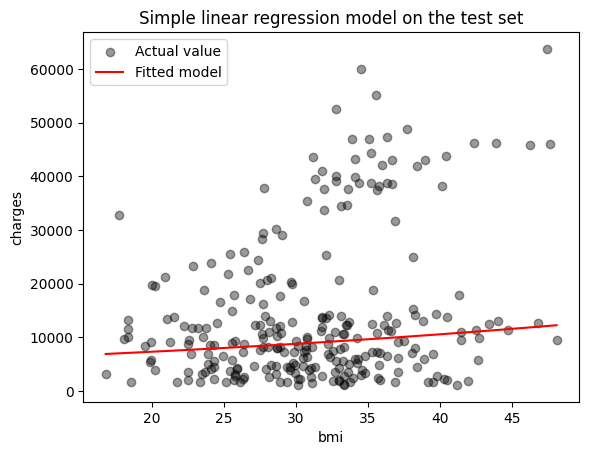

In [24]:
# Plot the test data and the fitted model, converted back to dollars
curve = insurance_test.sort_values('bmi')

plt.scatter(insurance_test['bmi'], insurance_test['charges'],
            color='black', alpha=0.4, label='Actual value')
plt.plot(curve['bmi'], curve['Prediction'],
         color='red', label='Fitted model')
plt.title('Simple linear regression model on the test set')
plt.xlabel('bmi')
plt.ylabel('charges')
plt.legend()
plt.show()

The black dots are the real clients of the test set and the red curve is what
the model predicts for each BMI, so the vertical distance between a dot and the
curve is the error made on that client. The curve bends instead of being a
straight line because the model was fitted on log(charges) and then converted
back to dollars: a constant percentage increase per BMI point becomes a curve
once it is read in dollars.

In [25]:
print(".................................Overestimated..................................")
# Clients whose actual charge is below the prediction
print(insurance_test[insurance_test['charges'] < insurance_test['Prediction']].head())

print(".................................Underestimated.................................")
# Clients whose actual charge is above the prediction
print(insurance_test[insurance_test['charges'] >= insurance_test['Prediction']].head())

.................................Overestimated..................................
        bmi    charges    Prediction    Residuals
1063  25.60  5708.8670   8108.672496 -2399.805496
237   38.39  4463.2051  10260.789436 -5797.584336
481   37.51  9304.7019  10095.943185  -791.241285
277   24.30  2150.4690   7916.966448 -5766.497448
415   35.64  7345.7266   9754.385341 -2408.658741
.................................Underestimated.................................
         bmi      charges   Prediction     Residuals
899   22.515   8688.85885  7661.101624   1027.757226
1255  36.385  11436.73815  9889.053465   1547.684685
298   34.390  38746.35510  9532.539308  29213.815792
240   36.670  38511.62830  9941.061077  28570.567223
706   28.690  10264.44210  8583.180817   1681.261283


The two tables list clients the model charged too much and too little. Read the
`charges` column against `Prediction`: the overestimated clients are ordinary
cases sitting a few thousand dollars below the line, while among the
underestimated ones there are clients paying 38,746 and 38,512 dollars against
predictions near 9,533 and 9,941. The model misses those by about four times
what it predicted.

That asymmetry is the same thing the residual plot showed as two bands. The
errors are not random noise spread evenly: there is a group of clients the model
cannot reach, and they are expensive for a reason `bmi` does not know about.

Finding that reason means looking outside the model. The lab asks for a simple
regression on `bmi`, so no other variable can enter the equation, but nothing
stops the notebook from using them as a diagnostic to explain why the model
fails. What follows is that diagnostic, not a second model.

The shape of the failure says what to look for. The two bands run roughly
parallel and are separated by a large jump in dollars, which is what a
categorical variable produces: a group that pays much more than the other at
every BMI. The three text columns of the dataset, `sex`, `smoker` and `region`,
are the candidates, and the one responsible has to meet two conditions: split
the clients into two groups, and make those groups pay very different amounts.

In [26]:
# Which qualitative variable separates the clients by what they are charged
for column in ['smoker', 'sex', 'region']:
    summary = insurance.groupby(column)['charges'].agg(['count', 'mean']).round(0)
    ratio = summary['mean'].max() / summary['mean'].min()
    print(f'{column}: {len(summary)} groups, dearest over cheapest = {ratio:.2f}x')
    print(summary, '\n')

smoker: 2 groups, dearest over cheapest = 3.80x
        count     mean
smoker                
no       1063   8441.0
yes       274  32050.0 

sex: 2 groups, dearest over cheapest = 1.11x
        count     mean
sex                   
female    662  12570.0
male      675  13975.0 

region: 4 groups, dearest over cheapest = 1.19x
           count     mean
region                   
northeast    324  13406.0
northwest    324  12451.0
southeast    364  14735.0
southwest    325  12347.0 



Only `smoker` meets both conditions. It splits the clients in two and the
smokers pay on average 3.8 times what the non smokers pay, 32,050 dollars
against 8,441. `sex` also splits in two, but both groups pay almost the same,
13,975 against 12,570, a ratio of 1.11, so it cannot be what separates the
bands. `region` fails the first condition, since it has four groups instead of
two, and its dearest region charges only 1.19 times the cheapest.

`smoker` is therefore the variable to inspect, and the next plot shows what it
does to the relationship between BMI and the amount charged.

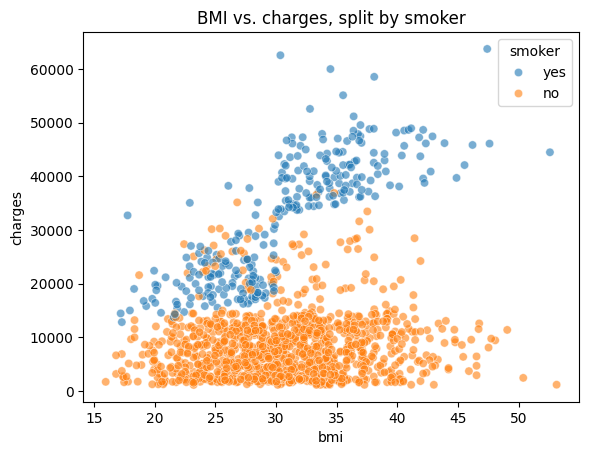

bmi-charges correlation, smokers only    : 0.806
bmi-charges correlation, non-smokers only: 0.084


In [27]:
sns.scatterplot(data=insurance, x='bmi', y='charges', hue='smoker', alpha=0.6)
plt.title('BMI vs. charges, split by smoker')
plt.show()

print("bmi-charges correlation, smokers only    :",
      round(insurance[insurance.smoker == 'yes'][['bmi', 'charges']].corr().iloc[0, 1], 3))
print("bmi-charges correlation, non-smokers only:",
      round(insurance[insurance.smoker == 'no'][['bmi', 'charges']].corr().iloc[0, 1], 3))

That is the explanation for the two bands. Among smokers, BMI does predict
the amount charged very well. Among non-smokers it barely matters. Mixing both
groups dilutes the real relationship.

### Prediction and model persistence

In [28]:
# Manual prediction for a client with a BMI of 30
client_bmi = 30

# The model returns log(charges), so it is converted back with the exponential
predicted_log = reg_charges.predict([[1, client_bmi]])[0]
print("Estimated charge:", round(np.exp(predicted_log), 2))

Estimated charge: 8792.64


The model estimates about 8,793 dollars for a client with a BMI of 30. That is
well below the average charge of the dataset, roughly 13,279 dollars, because a
model fitted on logarithms and converted back with the exponential returns the
typical client of that BMI rather than the average, and the average is pulled up
by the few very expensive clients. Given an R2 under 2 %, this number should be
read as the centre of a very wide range, not as a price.

In [29]:
# Save the model
joblib.dump(reg_charges, "model_insurance.pkl")

# Load the model
reg_loaded = joblib.load("model_insurance.pkl")

# Prediction using the model loaded from disk, converted back to dollars
print("Estimated charge with the loaded model:",
      round(np.exp(reg_loaded.predict([[1, client_bmi]])[0]), 2))

Estimated charge with the loaded model: 8792.64


## Results (CRISP-DM 6: Deployment)

The simple linear regression `log(charges) ~ bmi` is statistically
significant: the coefficient p-value is far below 0.05, so the relationship
between BMI and the amount charged exists and is positive. Each extra BMI point
is associated with roughly 1.9 % more on the premium.

The logarithmic transformation was necessary to reach that conclusion legally:
on the raw `charges` the residuals piled up on one side and their spread grew
with the fitted value, which invalidates the p-values the significance claim rests on.
After the transformation the residuals are even on both sides, so the inference
can be trusted.

The model is still not useful for prediction. On the training set it explains
under 2 % of the variation in `log(charges)`, and the average error is around
9,250 USD on amounts that average about 13,300 USD. Measured on the test set and
in dollars, where both versions answer the same question, its R2 comes out
negative, about -0.11: it predicts worse than always answering with the average
charge of the dataset. The transformation fixed the assumptions, not the fit.

The residual analysis and the plot split by `smoker` show the cause: the data
contains two different populations. Among smokers the BMI-charges correlation is
0.806 (very strong), while among non-smokers it is 0.084 (nonexistent). A model
with a single predictor cannot represent two behaviors that different.

Conclusion: this model is not recommended for pricing. Improving it would mean
moving to a multiple regression including `smoker` and `age`, which is what really
separates expensive clients from cheap ones. Also, predictions are only valid
inside the BMI range seen during training. Outside it the model would be
extrapolating.